# 02 — Pipeline de datos, fuga de información y línea base

Continúa el notebook `01_EDA_miotubos.ipynb`. Cubre los entregables:

| Entregable | Sección |
|---|---|
| Pipeline que produce train / val (y test) desde los originales → CSV | 1, 4, 6 (código en `src/myotubes/`, CLI en `scripts/run_pipeline.py`) |
| Definición de la etiqueta | 2 |
| Análisis de fuga de información | 3 |
| Tabla de desbalance | 5 |
| Línea base + métricas en validación: PR-AUC, ROC-AUC, recall con precisión ≥ 0.80, matriz de confusión | 7–8 |
| Figuras y tablas para el reporte | 9 (`reports/`) |

**Flujo de datos:**
`vt/` (originales, sin modificar) → `manifest.csv` → `splits/{train,val,test}.csv` → `sets/{train,val,test}/` (imágenes y máscaras redimensionadas).

> El conjunto de **prueba** se crea y se guarda, pero **no se usa** en este notebook. Todas las métricas son de **validación**.

In [3]:
# ====== CONFIGURA AQUÍ ======
RAW_DIR = r"C:\Users\dwigo\Documents\septimo_reto_2\vt"   # carpeta vt original
REBUILD_MANIFEST = False   # True para recalcular manifest.csv aunque ya exista
RUN_PREPARE = True         # escribe sets/{train,val,test} (imágenes a escala 0.5)
# ============================

import sys, json, warnings
from pathlib import Path

def repo_root():
    p = Path.cwd().resolve()
    for q in [p, *p.parents]:
        if (q / "config.json").exists() and (q / "src" / "myotubes").exists():
            return q
    raise FileNotFoundError("Abre el notebook dentro del repositorio (no encontré config.json)")

ROOT = repo_root()
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import cv2

from myotubes import load_config
from myotubes.io import find_root, read_gray, read_mask, parse_yolo, resize
from myotubes.manifest import build_manifest, save_manifest
from myotubes.leakage import (duplicate_pairs, duplicate_clusters, label_agreement,
                              leakage_rate, random_split_leakage, min_cross_distance)
from myotubes.split import run_split
from myotubes.prepare import prepare_sets
from myotubes.baseline import ClassicBaseline, PixelClassifierBaseline, load_items, predict_items
from myotubes.metrics import evaluate, per_image

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

CFG = load_config(ROOT / "config.json")
RAW = find_root(RAW_DIR)
OUT = ROOT / CFG["out_dir"]
REP = ROOT / "reports"; FIG = REP / "figures"
FIG.mkdir(parents=True, exist_ok=True)
SEED = CFG["seed"]; np.random.seed(SEED)

print("Repositorio:", ROOT)
print("Originales :", RAW)
print("Salida     :", OUT)
print(json.dumps(CFG, indent=1))

Repositorio: C:\Users\dwigo\Downloads\myotubes-seg\myotubes-seg
Originales : C:\Users\dwigo\Documents\septimo_reto_2\vt
Salida     : C:\Users\dwigo\Downloads\myotubes-seg\myotubes-seg\data\processed
{
 "raw_dir": "data/raw/vt",
 "out_dir": "data/processed",
 "seed": 42,
 "split": {
  "train": 0.7,
  "val": 0.15,
  "test": 0.15
 },
 "dhash_threshold": 6,
 "group_by_uuid": true,
 "dedupe": true,
 "exclude": {
  "missing_mask": true,
  "empty_masks": true,
  "max_instance_frac": 0.2
 },
 "prepare": {
  "scale": 0.5
 },
 "baseline": {
  "eval_scale": 0.25,
  "sato_sigmas": [
   2,
   3,
   4,
   5
  ],
  "min_object_px": 30,
  "train_pixels_per_class": 150000,
  "min_precision": 0.8
 }
}


## 1. Pipeline — paso 1: manifiesto de los datos originales

In [4]:
man_path = OUT / "manifest.csv"
if REBUILD_MANIFEST or not man_path.exists():
    manifest = build_manifest(RAW)
    save_manifest(manifest, OUT)
else:
    manifest = pd.read_csv(man_path)
print(f"manifest.csv: {len(manifest)} imágenes -> {man_path}")

resumen_manifest = pd.Series({
    "imágenes": len(manifest),
    "familia 'best' (hash-UUID_pozo_campo)": int((manifest["name_family"] == "best").sum()),
    "familia 'cell' (hash-cellNN)": int((manifest["name_family"] == "cell").sum()),
    "UUID distintos": int(manifest["uuid"].nunique()),
    "máscaras vacías": int(manifest["empty_mask"].sum()),
    "imágenes con polígonos fuera de [0,1]": int((manifest["n_out_of_range"] > 0).sum()),
    f"imágenes con una caja > {CFG['exclude']['max_instance_frac']:.0%} de la imagen":
        int((manifest["max_inst_frac"] > CFG["exclude"]["max_instance_frac"]).sum()),
}, name="n")
display(resumen_manifest.to_frame())
display(manifest.head(3))

manifiesto:   0%|          | 0/306 [00:00<?, ?it/s]

manifest.csv: 306 imágenes -> C:\Users\dwigo\Downloads\myotubes-seg\myotubes-seg\data\processed\manifest.csv


,n
imágenes,306
familia 'best' (hash-UUID_pozo_campo),254
familia 'cell' (hash-cellNN),51
UUID distintos,30
máscaras vacías,34
"imágenes con polígonos fuera de [0,1]",28
imágenes con una caja > 20% de la imagen,3


,stem,image,mask,label,verification,height,width,dtype,int_mean,int_std,...,field,cell_id,name_family,px_fg,frac_fg,n_inst,n_out_of_range,n_tiny,max_inst_frac,empty_mask
0,002bbf6f-6a55a585-2551-49dd-be42-a9371d0c40ea_...,images/002bbf6f-6a55a585-2551-49dd-be42-a9371d...,masks_png/002bbf6f-6a55a585-2551-49dd-be42-a93...,labels/002bbf6f-6a55a585-2551-49dd-be42-a9371d...,verification/002bbf6f-6a55a585-2551-49dd-be42-...,1944,2592,uint8,143.602319,31.056758,...,02_06,None,best,0,0.000000,0,0,0,0.000000,True
1,00538475-f23e64e2-8f62-4391-bd64-e8ecbaafc9be_...,images/00538475-f23e64e2-8f62-4391-bd64-e8ecba...,masks_png/00538475-f23e64e2-8f62-4391-bd64-e8e...,labels/00538475-f23e64e2-8f62-4391-bd64-e8ecba...,verification/00538475-f23e64e2-8f62-4391-bd64-...,1944,2592,uint8,153.504178,31.181938,...,02_06,None,best,36142,0.007173,2,0,0,0.005063,False
2,0062917b-195893df-aa40-4944-8592-2fa62f94d608_...,images/0062917b-195893df-aa40-4944-8592-2fa62f...,masks_png/0062917b-195893df-aa40-4944-8592-2fa...,labels/0062917b-195893df-aa40-4944-8592-2fa62f...,verification/0062917b-195893df-aa40-4944-8592-...,1944,2592,uint8,155.762809,32.232937,...,02_03,None,best,85475,0.016963,22,1,0,0.003644,False


## 2. Definición de la etiqueta

| | |
|---|---|
| **Tarea** | Segmentación semántica binaria a nivel píxel. |
| **Entrada X** | Imagen de microscopía en escala de grises, `uint8`, 1 canal, 2592×1944 (`images/`). |
| **Etiqueta Y** | Máscara `masks_png/<nombre>.png`: **1 = miotubo**, **0 = fondo**. Es la unión de los polígonos de `labels/` (formato YOLO-Seg). |
| **Qué significa "1"** | Que el píxel cae dentro de un **rectángulo anotado** (4 vértices) colocado sobre un **tramo** de miotubo. **No** es el contorno completo del miotubo. |
| **Qué significa "0"** | Fondo **o** miotubo no anotado. La clase 0 tiene **ruido de etiqueta**: contiene miotubos reales sin anotar. |
| **Exclusiones** (documentadas, sin modificar originales) | 1) máscaras vacías: mezclan negativos reales con imágenes sin anotar; 2) imágenes con una caja > 20 % del área, que son errores de anotación; 3) copias duplicadas, de las que se conserva una por clúster. |
| **Resolución de evaluación de la línea base** | ×0.25 (648×486). Imagen con `INTER_AREA` y máscara con vecino más cercano. El ancho típico anotado (~40 px) queda en ~10 px. |
| **Clases de la matriz de confusión** | K = 2: {fondo, miotubo}. El código de métricas es genérico para K clases. |

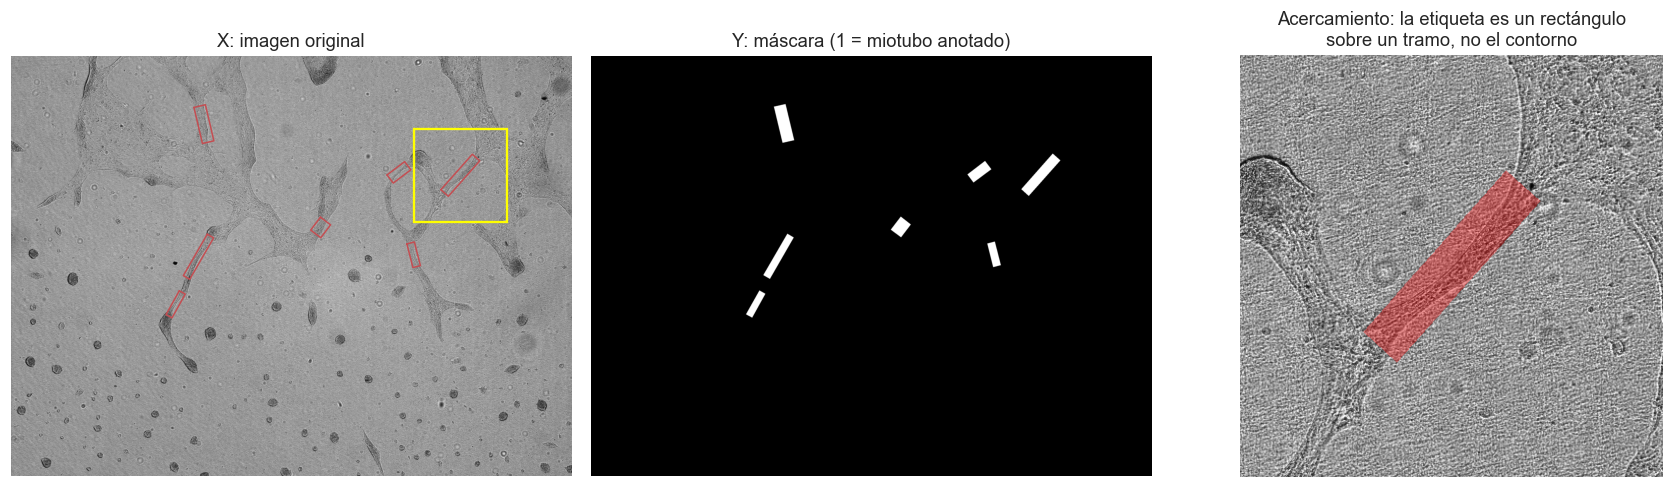

Ejemplo: 206b4a49-4bbba11f-35de-40fd-b133-6da58bccb122_A2_03_03_Best


In [5]:
# Ejemplo visual de la etiqueta: imagen, máscara y acercamiento a una caja anotada
cand = manifest[(~manifest["empty_mask"]) & (manifest["max_inst_frac"] < 0.05)]
ej = cand.sort_values("n_inst").iloc[len(cand) // 2]
img = read_gray(RAW / ej["image"]); m = read_mask(RAW / ej["mask"])
polys, _ = parse_yolo(RAW / ej["label"])
H, W = img.shape

# caja más grande para el acercamiento
areas = [cv2.contourArea((p * [W, H]).astype(np.float32)) for _, p in polys]
pts = (polys[int(np.argmax(areas))][1] * [W, H])
cx, cy = pts.mean(0).astype(int); r = int(max(np.ptp(pts[:, 0]), np.ptp(pts[:, 1])) * 0.9) + 40
x0, x1 = max(cx - r, 0), min(cx + r, W); y0, y1 = max(cy - r, 0), min(cy + r, H)

fig, ax = plt.subplots(1, 3, figsize=(16, 4.6))
ax[0].imshow(img, cmap="gray"); ax[0].set_title("X: imagen original")
for _, p in polys:
    q = np.vstack([p, p[:1]]) * [W, H]; ax[0].plot(q[:, 0], q[:, 1], "r-", lw=1)
ax[0].add_patch(plt.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, ec="yellow", lw=1.5))
ax[1].imshow(m, cmap="gray", vmin=0, vmax=1); ax[1].set_title("Y: máscara (1 = miotubo anotado)")
ax[2].imshow(img[y0:y1, x0:x1], cmap="gray")
ax[2].imshow(np.ma.masked_where(m[y0:y1, x0:x1] == 0, m[y0:y1, x0:x1]), cmap="autumn", alpha=.35)
ax[2].set_title("Acercamiento: la etiqueta es un rectángulo\nsobre un tramo, no el contorno")
for a in ax: a.axis("off")
plt.tight_layout(); plt.savefig(FIG / "fig_etiqueta.png", bbox_inches="tight", dpi=150); plt.show()
print("Ejemplo:", ej["stem"])

## 3. Análisis de fuga de información

En el EDA vimos que la misma imagen aparece varias veces con nombres distintos. Si una copia cae en train y otra en validación, el modelo "ve" la respuesta y las métricas quedan infladas. Este análisis:
1. detecta copias con dHash (Hamming ≤ umbral) y por mismo `cellNN`;
2. revisa si las copias tienen la **misma anotación**;
3. compara cuánta fuga habría con una **partición aleatoria ingenua** frente a la **partición agrupada** del pipeline.

In [6]:
pairs, D = duplicate_pairs(manifest, CFG["dhash_threshold"])
clusters = duplicate_clusters(manifest, pairs)
tam = clusters.value_counts()

fuga_dup = pd.Series({
    "pares casi duplicados (Hamming ≤ %d)" % CFG["dhash_threshold"]: len(pairs),
    "pares idénticos (Hamming = 0)": int((pairs["hamming"] == 0).sum()),
    "clústeres con ≥ 2 copias": int((tam > 1).sum()),
    "imágenes involucradas en copias": int(tam[tam > 1].sum()),
    "imágenes únicas (1 por clúster)": int(len(tam)),
    "copia más repetida (veces)": int(tam.max()),
}, name="n")
display(fuga_dup.to_frame())

# Pares duplicados con UUID distinto (el UUID no basta para agrupar)
u = manifest.set_index("stem")["uuid"]
pairs["mismo_uuid"] = [u[a] == u[b] if pd.notna(u[a]) and pd.notna(u[b]) else np.nan
                       for a, b in zip(pairs["stem_a"], pairs["stem_b"])]
print("Pares 'best' con UUID distinto:", int((pairs["mismo_uuid"] == False).sum()),
      "| con el mismo UUID:", int((pairs["mismo_uuid"] == True).sum()))

# ¿Las copias se anotaron igual?
agree = label_agreement(manifest, pairs, RAW, scale=0.25)
pairs = pairs.merge(agree[["stem_a", "stem_b", "iou_mascaras"]], on=["stem_a", "stem_b"], how="left")
print("\nIoU entre máscaras de copias:")
display(pairs["iou_mascaras"].describe().to_frame().T.round(3))
print("Pares con anotación distinta (IoU < 0.9):", int((pairs["iou_mascaras"] < 0.9).sum()))
display(pairs.sort_values("iou_mascaras").head(8))

,n
pares casi duplicados (Hamming ≤ 6),117
pares idénticos (Hamming = 0),16
clústeres con ≥ 2 copias,54
imágenes involucradas en copias,138
imágenes únicas (1 por clúster),222
copia más repetida (veces),14


Pares 'best' con UUID distinto: 95 | con el mismo UUID: 6

IoU entre máscaras de copias:


,count,mean,std,min,25%,50%,75%,max
iou_mascaras,117.0,0.191,0.261,0.0,0.001,0.099,0.249,1.0


Pares con anotación distinta (IoU < 0.9): 109


,stem_a,stem_b,hamming,mismo_uuid,iou_mascaras
116,00538475-f23e64e2-8f62-4391-bd64-e8ecbaafc9be_...,994c6cd3-88797675-e851-4bb9-93df-0d446823b511_...,6,False,0.0
88,1c2ebfc5-d62536a3-1443-496e-a189-0c39acfa33eb_...,bd19c30c-ca6c3fb1-be85-468c-9b60-7d9e94829e57_...,6,False,0.0
23,36b58105-6a55a585-2551-49dd-be42-a9371d0c40ea_...,c3643a88-e5f15412-aaff-475b-a3c6-511f84257343_...,2,False,0.0
63,a7ef3fdf-35f892c1-da41-4a26-afbf-cb846cdf7436_...,d55063fd-4bbba11f-35de-40fd-b133-6da58bccb122_...,4,False,0.0
87,bd19c30c-ca6c3fb1-be85-468c-9b60-7d9e94829e57_...,c3643a88-e5f15412-aaff-475b-a3c6-511f84257343_...,6,False,0.0
86,0cb7e1ad-ca6c3fb1-be85-468c-9b60-7d9e94829e57_...,bd19c30c-ca6c3fb1-be85-468c-9b60-7d9e94829e57_...,6,True,0.0
84,1841443f-4b2b8615-75d4-4b2e-bccd-5731cc9b8ffc_...,42d9a546-b1db384e-b79a-4fa0-a47d-aa0aebe3a2bd_...,6,False,0.0
89,c3643a88-e5f15412-aaff-475b-a3c6-511f84257343_...,c9cd72fd-6a55a585-2551-49dd-be42-a9371d0c40ea_...,6,False,0.0


## 4. Partición agrupada (pipeline — paso 2) y fuga: ingenua vs. agrupada

{
 "modo": "duplicados + cell_id",
 "aviso": "Agrupar por UUID genera un grupo con 44% de las imágenes; se usa solo duplicados + cell_id.",
 "grupo_mayor_frac": 0.0457516339869281,
 "n_pares_duplicados": 117
}


,imágenes
split,
train,136
duplicado_descartado,74
excluida,37
val,30
test,29


,excluidas por
excluded_reason,
mascara_vacia,34
caja_gigante(>20%),3


,partición,% de imágenes de val con copia en train
0,aleatoria ingenua (50 semillas),36.2% ± 6.8% (máx 56.5%)
1,agrupada (pipeline),0.0%


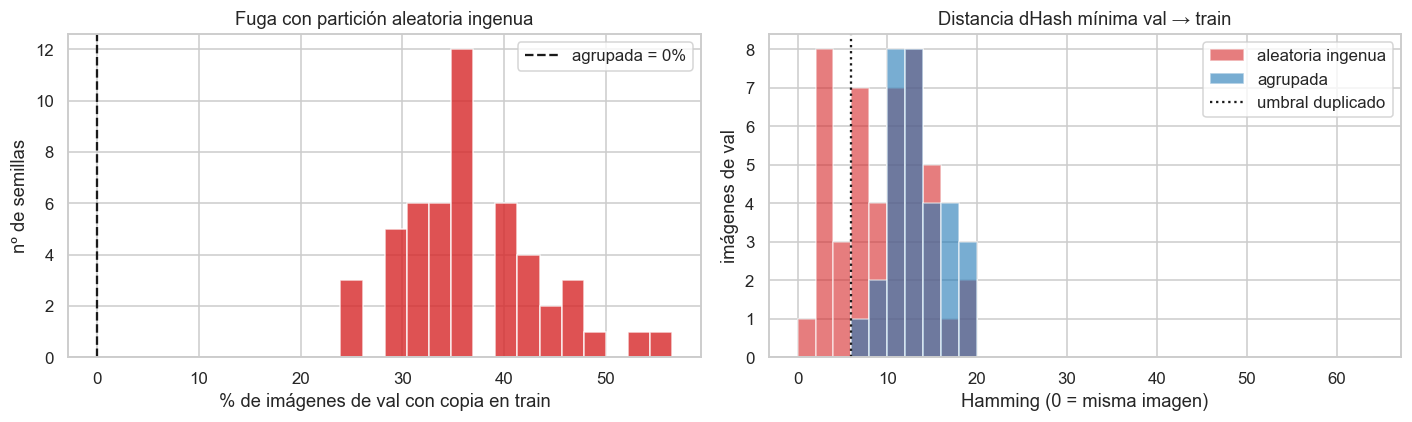

In [7]:
df_split, pairs_split, info_split = run_split(manifest, CFG, OUT)
print(json.dumps(info_split, indent=1, ensure_ascii=False))
display(df_split["split"].value_counts().to_frame("imágenes"))
display(df_split.loc[df_split["excluded_reason"].fillna("") != "", "excluded_reason"].value_counts().to_frame("excluidas por"))

split_s = df_split.set_index("stem")["split"]
naive = random_split_leakage(manifest["stem"], pairs, CFG["split"], seeds=range(50))
agrup = leakage_rate(split_s, pairs, "val", "train")

tabla_fuga = pd.DataFrame({
    "partición": ["aleatoria ingenua (50 semillas)", "agrupada (pipeline)"],
    "% de imágenes de val con copia en train": [f"{naive.mean():.1%} ± {naive.std():.1%} (máx {naive.max():.1%})",
                                                f"{agrup:.1%}"],
})
display(tabla_fuga)

# Distancia dHash mínima de cada imagen de val a train
rng = np.random.default_rng(SEED)
perm = rng.permutation(manifest["stem"]); n_tr = round(.7 * len(perm)); n_va = round(.15 * len(perm))
naive_s = pd.Series("test", index=perm); naive_s.iloc[:n_tr] = "train"; naive_s.iloc[n_tr:n_tr + n_va] = "val"
d_naive = min_cross_distance(D, manifest, naive_s)
d_group = min_cross_distance(D, manifest, split_s)

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].hist(naive * 100, bins=15, color="tab:red", alpha=.8)
ax[0].axvline(agrup * 100, color="k", ls="--", label=f"agrupada = {agrup:.0%}")
ax[0].set(title="Fuga con partición aleatoria ingenua", xlabel="% de imágenes de val con copia en train",
          ylabel="nº de semillas"); ax[0].legend()
bins = np.arange(0, 66, 2)
ax[1].hist(d_naive, bins=bins, alpha=.6, label="aleatoria ingenua", color="tab:red")
ax[1].hist(d_group, bins=bins, alpha=.6, label="agrupada", color="tab:blue")
ax[1].axvline(CFG["dhash_threshold"], color="k", ls=":", label="umbral duplicado")
ax[1].set(title="Distancia dHash mínima val → train", xlabel="Hamming (0 = misma imagen)", ylabel="imágenes de val")
ax[1].legend()
plt.tight_layout(); plt.savefig(FIG / "fig_fuga.png", bbox_inches="tight", dpi=150); plt.show()

tabla_fuga.to_csv(REP / "tabla_fuga.csv", index=False)
pairs.to_csv(REP / "pares_duplicados.csv", index=False)

In [8]:
# Verificaciones de la partición
asig = df_split[df_split["split"].isin(CFG["split"].keys())]
assert asig.groupby("group")["split"].nunique().max() == 1, "Un grupo quedó en dos particiones"
for a in CFG["split"]:
    for b in CFG["split"]:
        if a < b:
            inter = set(asig.loc[asig["split"] == a, "group"]) & set(asig.loc[asig["split"] == b, "group"])
            print(f"grupos compartidos {a}-{b}: {len(inter)}")
print("Archivos de partición:", sorted(p.name for p in (OUT / "splits").glob("*.csv")))
display(asig.groupby("split").agg(imagenes=("stem", "size"), grupos=("group", "nunique"),
                                  uuids=("uuid", "nunique")).T)

grupos compartidos train-val: 0
grupos compartidos test-train: 0
grupos compartidos test-val: 0
Archivos de partición: ['all.csv', 'descartadas.csv', 'duplicate_pairs.csv', 'test.csv', 'train.csv', 'val.csv']


split,test,train,val
imagenes,29,136,30
grupos,29,136,30
uuids,17,26,13


## 5. Tabla de desbalance

,imagenes,instancias,px_miotubo_M,px_fondo_M,pct_miotubo,ratio_fondo_miotubo,mediana_pct_por_imagen,imagenes_vacias,pos_weight_BCE
conjunto,,,,,,,,,
original (todas),306,2148,27.13,1514.76,1.76,55.84,0.86,34,55.84
train,136,1144,11.88,673.40,1.73,56.68,1.29,0,56.68
val,30,218,2.36,148.80,1.56,62.99,0.96,0,62.99
test,29,327,2.20,143.93,1.50,65.45,1.22,0,65.45


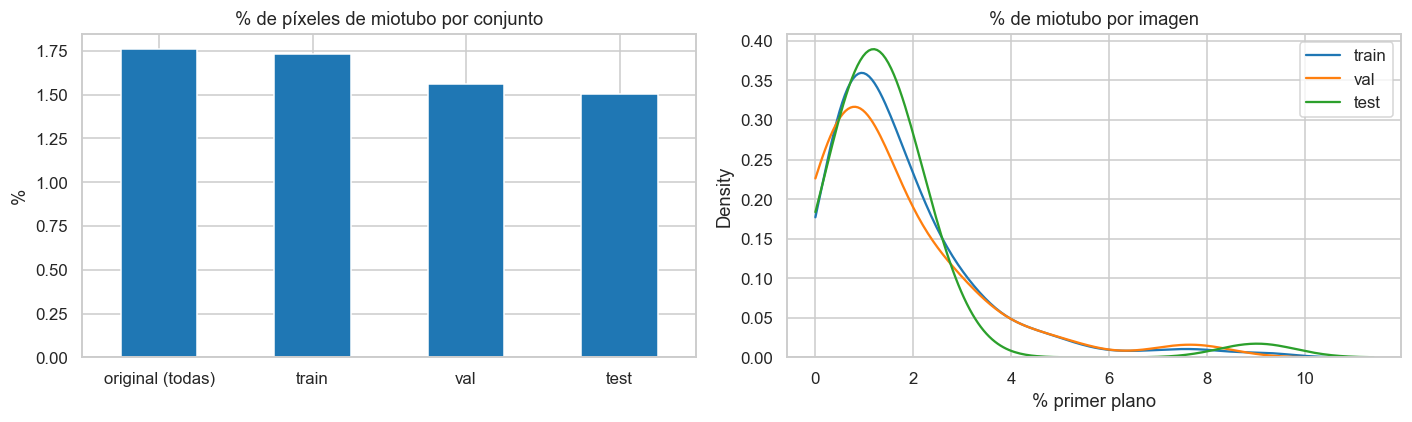

In [9]:
def fila_desbalance(d, nombre):
    px = (d["height"] * d["width"]).sum(); fg = d["px_fg"].sum()
    return dict(conjunto=nombre, imagenes=len(d), instancias=int(d["n_inst"].sum()),
                px_miotubo_M=fg / 1e6, px_fondo_M=(px - fg) / 1e6,
                pct_miotubo=100 * fg / px, ratio_fondo_miotubo=(px - fg) / max(fg, 1),
                mediana_pct_por_imagen=100 * d["frac_fg"].median(),
                imagenes_vacias=int(d["empty_mask"].sum()))

filas = [fila_desbalance(manifest, "original (todas)")]
filas += [fila_desbalance(asig[asig["split"] == s], s) for s in CFG["split"]]
tabla_desb = pd.DataFrame(filas).set_index("conjunto")
tabla_desb["pos_weight_BCE"] = tabla_desb["ratio_fondo_miotubo"]
display(tabla_desb.round(2))
tabla_desb.round(4).to_csv(REP / "tabla_desbalance.csv")

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
tabla_desb["pct_miotubo"].plot.bar(ax=ax[0], color="tab:blue")
ax[0].set(title="% de píxeles de miotubo por conjunto", ylabel="%", xlabel=""); ax[0].tick_params(axis="x", rotation=0)
for s, c in zip(CFG["split"], ["tab:blue", "tab:orange", "tab:green"]):
    sns.kdeplot(100 * asig.loc[asig["split"] == s, "frac_fg"], ax=ax[1], label=s, color=c, clip=(0, None))
ax[1].set(title="% de miotubo por imagen", xlabel="% primer plano"); ax[1].legend()
plt.tight_layout(); plt.savefig(FIG / "fig_desbalance.png", bbox_inches="tight", dpi=150); plt.show()

## 6. Pipeline — paso 3: conjuntos de entrenamiento y validación

In [10]:
if RUN_PREPARE:
    sets = prepare_sets(RAW, OUT, tuple(CFG["split"]), CFG["prepare"]["scale"])
    for k, v in sets.items():
        print(f"{k:5s}: {len(v)} imágenes  {v['height'].iloc[0]}x{v['width'].iloc[0]}  -> {OUT / 'sets' / k}")
else:
    print("RUN_PREPARE=False: se omitió la escritura de sets/. Equivale a:")
print("\nCLI equivalente:\n  python scripts/run_pipeline.py --config config.json --raw \"<ruta vt>\"")

preparando train:   0%|          | 0/136 [00:00<?, ?it/s]

preparando val:   0%|          | 0/30 [00:00<?, ?it/s]

preparando test:   0%|          | 0/29 [00:00<?, ?it/s]

train: 136 imágenes  972x1296  -> C:\Users\dwigo\Downloads\myotubes-seg\myotubes-seg\data\processed\sets\train
val  : 30 imágenes  972x1296  -> C:\Users\dwigo\Downloads\myotubes-seg\myotubes-seg\data\processed\sets\val
test : 29 imágenes  972x1296  -> C:\Users\dwigo\Downloads\myotubes-seg\myotubes-seg\data\processed\sets\test

CLI equivalente:
  python scripts/run_pipeline.py --config config.json --raw "<ruta vt>"


## 7. Línea base sin deep learning

- **A. Clásica:** normalización por percentiles → filtro de crestas oscuras **Sato** (σ = 2–5 px a escala ×0.25) → umbral → apertura 3×3 → eliminación de objetos < 30 px.
- **B. Clasificador de píxeles:** 6 características hechas a mano (intensidad, dos suavizados gaussianos, desviación local, oscuridad respecto al fondo local, Sato) + `HistGradientBoostingClassifier`, entrenado con píxeles balanceados de **train**.

En ambas, la escala del score y el **umbral** se fijan **solo con train** (el que maximiza F1, re-ponderado a la prevalencia real). Validación se usa únicamente para reportar.

In [11]:
B = CFG["baseline"]; S = B["eval_scale"]
tr_df = asig[asig["split"] == "train"]; va_df = asig[asig["split"] == "val"]
train_items = load_items(tr_df, RAW, S)
val_items = load_items(va_df, RAW, S)
print(f"train: {len(train_items)} imgs | val: {len(val_items)} imgs | tamaño {val_items[0]['img'].shape}")

modelos = {
    "A_clasica": ClassicBaseline(B["sato_sigmas"], B["min_object_px"], SEED),
    "B_pixeles": PixelClassifierBaseline(B["sato_sigmas"], B["min_object_px"], SEED),
}
for k, mdl in modelos.items():
    mdl.fit(train_items, B["train_pixels_per_class"])
    print(f"{mdl.name}: umbral = {mdl.threshold_:.4f} | F1 en train = {mdl.train_f1_:.3f}")

cargando:   0%|          | 0/136 [00:00<?, ?it/s]

cargando:   0%|          | 0/30 [00:00<?, ?it/s]

train: 136 imgs | val: 30 imgs | tamaño (486, 648)


Sato train:   0%|          | 0/136 [00:00<?, ?it/s]

Clásica (Sato + umbral + morfología): umbral = 0.3780 | F1 en train = 0.163


características train:   0%|          | 0/136 [00:00<?, ?it/s]

Clasificador de píxeles (características + HGB): umbral = 0.8890 | F1 en train = 0.307


## 8. Evaluación en validación

In [12]:
preds, resultados = {}, {}
for k, mdl in modelos.items():
    preds[k] = predict_items(mdl, val_items)
    resultados[k] = evaluate(val_items, preds[k], min_precision=B["min_precision"])

tabla_metricas = pd.DataFrame({modelos[k].name: r["summary"] for k, r in resultados.items()}).T
display(tabla_metricas.round(4))
tabla_metricas.round(4).to_csv(REP / "metricas_validacion.csv")

for k, r in resultados.items():
    rap = r["recall_at_precision"]
    msg = (f"recall = {rap['recall']:.3f} con precisión {rap['precision']:.3f} (umbral {rap['threshold']:.4f})"
           if rap["alcanzable"] else "la curva PR nunca alcanza precisión ≥ 0.80 → recall = 0")
    print(f"{modelos[k].name}: {msg}")

predicción:   0%|          | 0/30 [00:00<?, ?it/s]

predicción:   0%|          | 0/30 [00:00<?, ?it/s]

,PR-AUC (AP),ROC-AUC,recall@P>=0.80,umbral@P,PR-AUC azar (prevalencia),IoU miotubo,Dice miotubo,precision miotubo,recall miotubo,mIoU
Clásica (Sato + umbral + morfología),0.0666,0.7202,0.0000,NaN,0.0156,0.0831,0.1535,0.1008,0.3222,0.5137
Clasificador de píxeles (características + HGB),0.1763,0.8968,0.0003,0.9822,0.0156,0.1650,0.2832,0.3084,0.2618,0.5721


Clásica (Sato + umbral + morfología): la curva PR nunca alcanza precisión ≥ 0.80 → recall = 0
Clasificador de píxeles (características + HGB): recall = 0.000 con precisión 0.825 (umbral 0.9822)


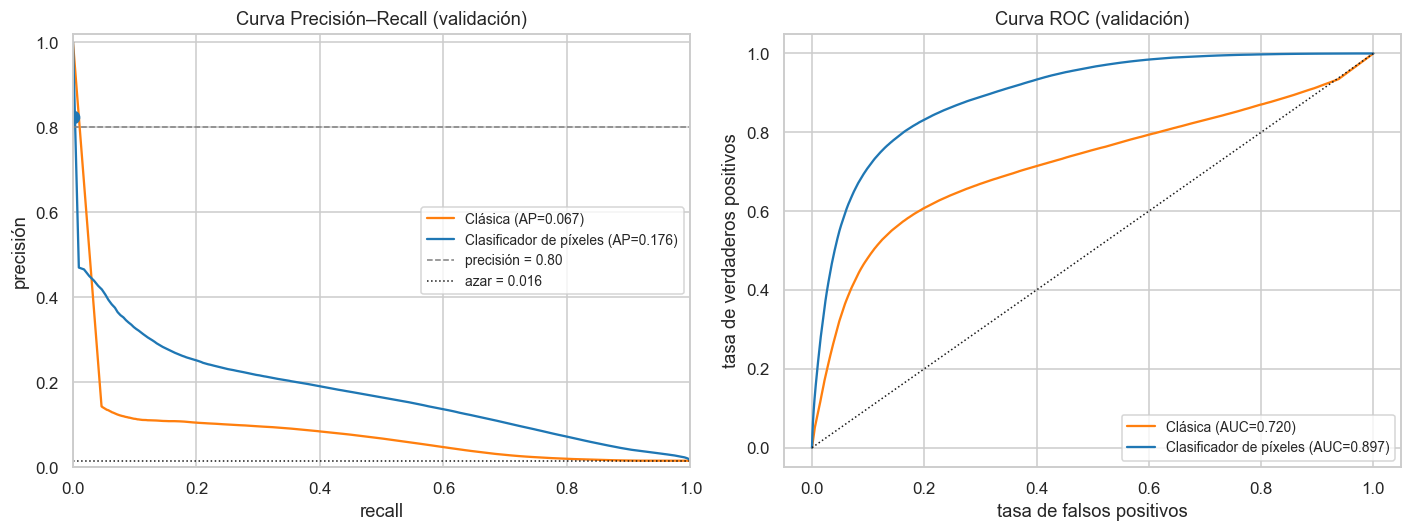

In [13]:
def _thin(x, y, n=4000):
    if len(x) <= n: return x, y
    i = np.linspace(0, len(x) - 1, n).astype(int); return x[i], y[i]

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
colores = {"A_clasica": "tab:orange", "B_pixeles": "tab:blue"}
for k, r in resultados.items():
    p, rc, _ = r["curves"]["pr"]; rc_, p_ = _thin(rc, p)
    ax[0].plot(rc_, p_, color=colores[k], label=f"{modelos[k].name.split(' (')[0]} (AP={r['summary']['PR-AUC (AP)']:.3f})")
    rap = r["recall_at_precision"]
    if rap["alcanzable"]:
        ax[0].plot(rap["recall"], rap["precision"], "o", color=colores[k], ms=8)
    fpr, tpr, _ = r["curves"]["roc"]; f_, t_ = _thin(fpr, tpr)
    ax[1].plot(f_, t_, color=colores[k], label=f"{modelos[k].name.split(' (')[0]} (AUC={r['summary']['ROC-AUC']:.3f})")
prev = resultados["A_clasica"]["summary"]["PR-AUC azar (prevalencia)"]
ax[0].axhline(B["min_precision"], color="gray", ls="--", lw=1, label=f"precisión = {B['min_precision']:.2f}")
ax[0].axhline(prev, color="k", ls=":", lw=1, label=f"azar = {prev:.3f}")
ax[0].set(title="Curva Precisión–Recall (validación)", xlabel="recall", ylabel="precisión", xlim=(0, 1), ylim=(0, 1.02))
ax[0].legend(fontsize=9)
ax[1].plot([0, 1], [0, 1], "k:", lw=1)
ax[1].set(title="Curva ROC (validación)", xlabel="tasa de falsos positivos", ylabel="tasa de verdaderos positivos")
ax[1].legend(fontsize=9)
plt.tight_layout(); plt.savefig(FIG / "fig_pr_roc.png", bbox_inches="tight", dpi=150); plt.show()

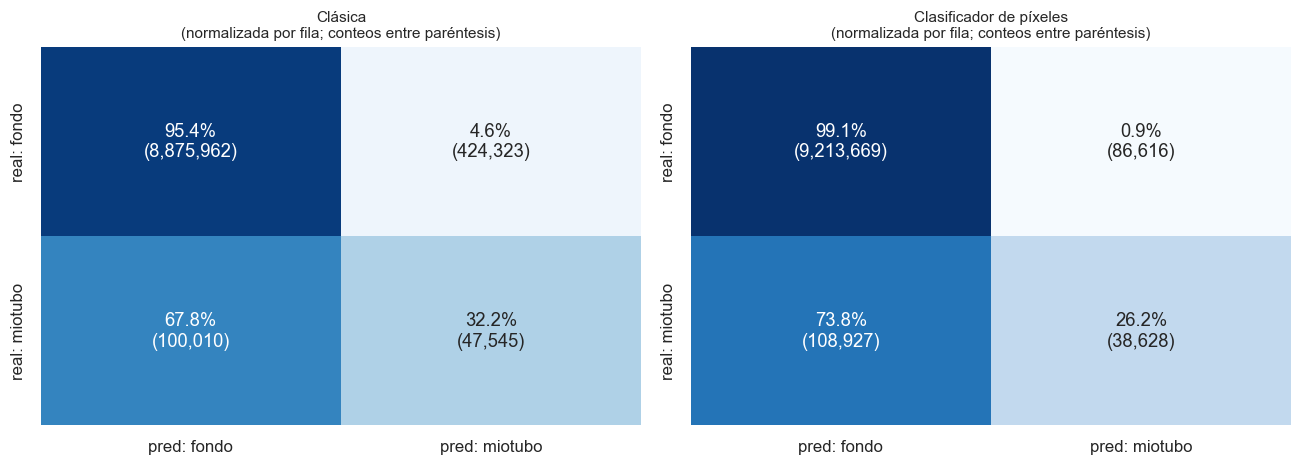

Clásica (Sato + umbral + morfología)


,pred: fondo,pred: miotubo
real: fondo,8875962,424323
real: miotubo,100010,47545


,IoU,Dice/F1,precision,recall,soporte_px
fondo,0.9442,0.9713,0.9889,0.9544,9300285
miotubo,0.0831,0.1535,0.1008,0.3222,147555


Clasificador de píxeles (características + HGB)


,pred: fondo,pred: miotubo
real: fondo,9213669,86616
real: miotubo,108927,38628


,IoU,Dice/F1,precision,recall,soporte_px
fondo,0.9792,0.9895,0.9883,0.9907,9300285
miotubo,0.1650,0.2832,0.3084,0.2618,147555


In [14]:
# Matriz de confusión (píxeles de validación, umbral fijado en train)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.4))
for a, (k, r) in zip(ax, resultados.items()):
    cn, cc = r["confusion_norm"], r["confusion"]
    annot = np.array([[f"{cn.iloc[i, j]:.1%}\n({cc.iloc[i, j]:,})" for j in range(cc.shape[1])]
                      for i in range(cc.shape[0])])
    sns.heatmap(cn, annot=annot, fmt="", cmap="Blues", vmin=0, vmax=1, cbar=False, ax=a)
    a.set_title(modelos[k].name.split(" (")[0] + "\n(normalizada por fila; conteos entre paréntesis)", fontsize=10)
    a.set_ylabel(""); a.set_xlabel("")
plt.tight_layout(); plt.savefig(FIG / "fig_confusion.png", bbox_inches="tight", dpi=150); plt.show()

for k, r in resultados.items():
    print(modelos[k].name); display(r["confusion"]); display(r["per_class"].round(4))
    r["confusion"].to_csv(REP / f"confusion_{k}.csv"); r["per_class"].round(4).to_csv(REP / f"por_clase_{k}.csv")

modelo           A_clasica  B_pixeles
IoU       count     30.000     30.000
          mean       0.069      0.131
          std        0.054      0.096
          min        0.000      0.000
          25%        0.025      0.052
          50%        0.052      0.120
          75%        0.102      0.199
          max        0.199      0.340
Dice      count     30.000     30.000
          mean       0.125      0.220
          std        0.092      0.148
          min        0.001      0.000
          25%        0.049      0.098
          50%        0.099      0.214
          75%        0.185      0.332
          max        0.332      0.507
precision count     30.000     30.000
          mean       0.091      0.259
          std        0.083      0.205
          min        0.000      0.000
          25%        0.029      0.100
          50%        0.061      0.241
          75%        0.135      0.415
          max        0.338      0.767
recall    count     30.000     30.000
          mean       0.297      0.245
          std        0.165      0.164
          min        0.031      0.000
          25%        0.144      0.118
          50%        0.313      0.267
          75%        0.406      0.388
          max        0.654      0.504

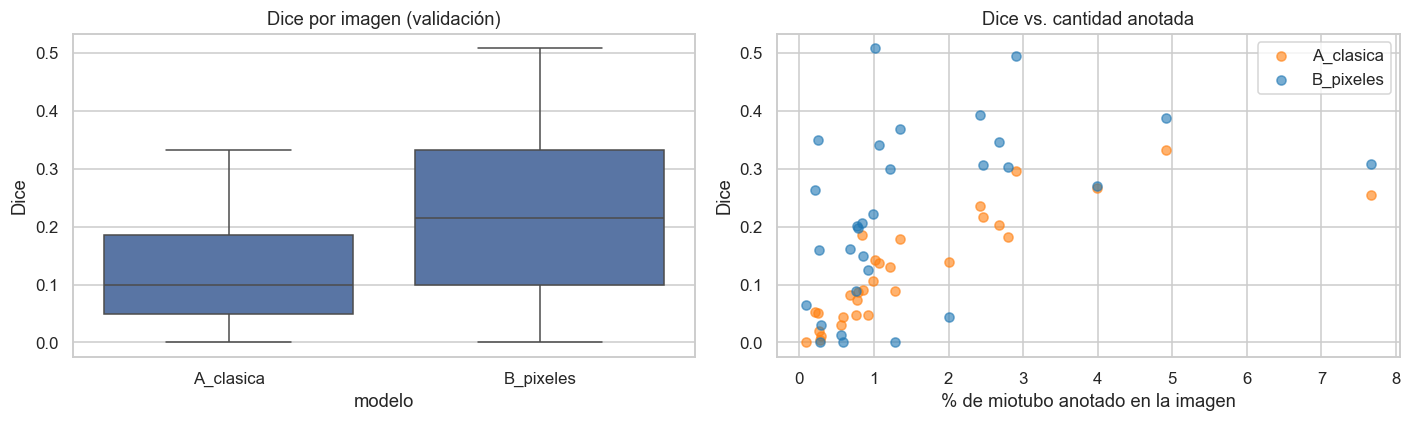

In [15]:
# Desempeño por imagen y relación con el % de miotubo
pi = {k: per_image(val_items, preds[k]).assign(modelo=k) for k in modelos}
pi_all = pd.concat(pi.values())
display(pi_all.groupby("modelo")[["IoU", "Dice", "precision", "recall"]].describe().T.round(3))

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.boxplot(data=pi_all, x="modelo", y="Dice", ax=ax[0]); ax[0].set_title("Dice por imagen (validación)")
for k in modelos:
    ax[1].scatter(100 * pi[k]["frac_fg"], pi[k]["Dice"], alpha=.6, label=k, color=colores[k])
ax[1].set(xlabel="% de miotubo anotado en la imagen", ylabel="Dice", title="Dice vs. cantidad anotada"); ax[1].legend()
plt.tight_layout(); plt.savefig(FIG / "fig_por_imagen.png", bbox_inches="tight", dpi=150); plt.show()
pi_all.to_csv(REP / "metricas_por_imagen_val.csv", index=False)

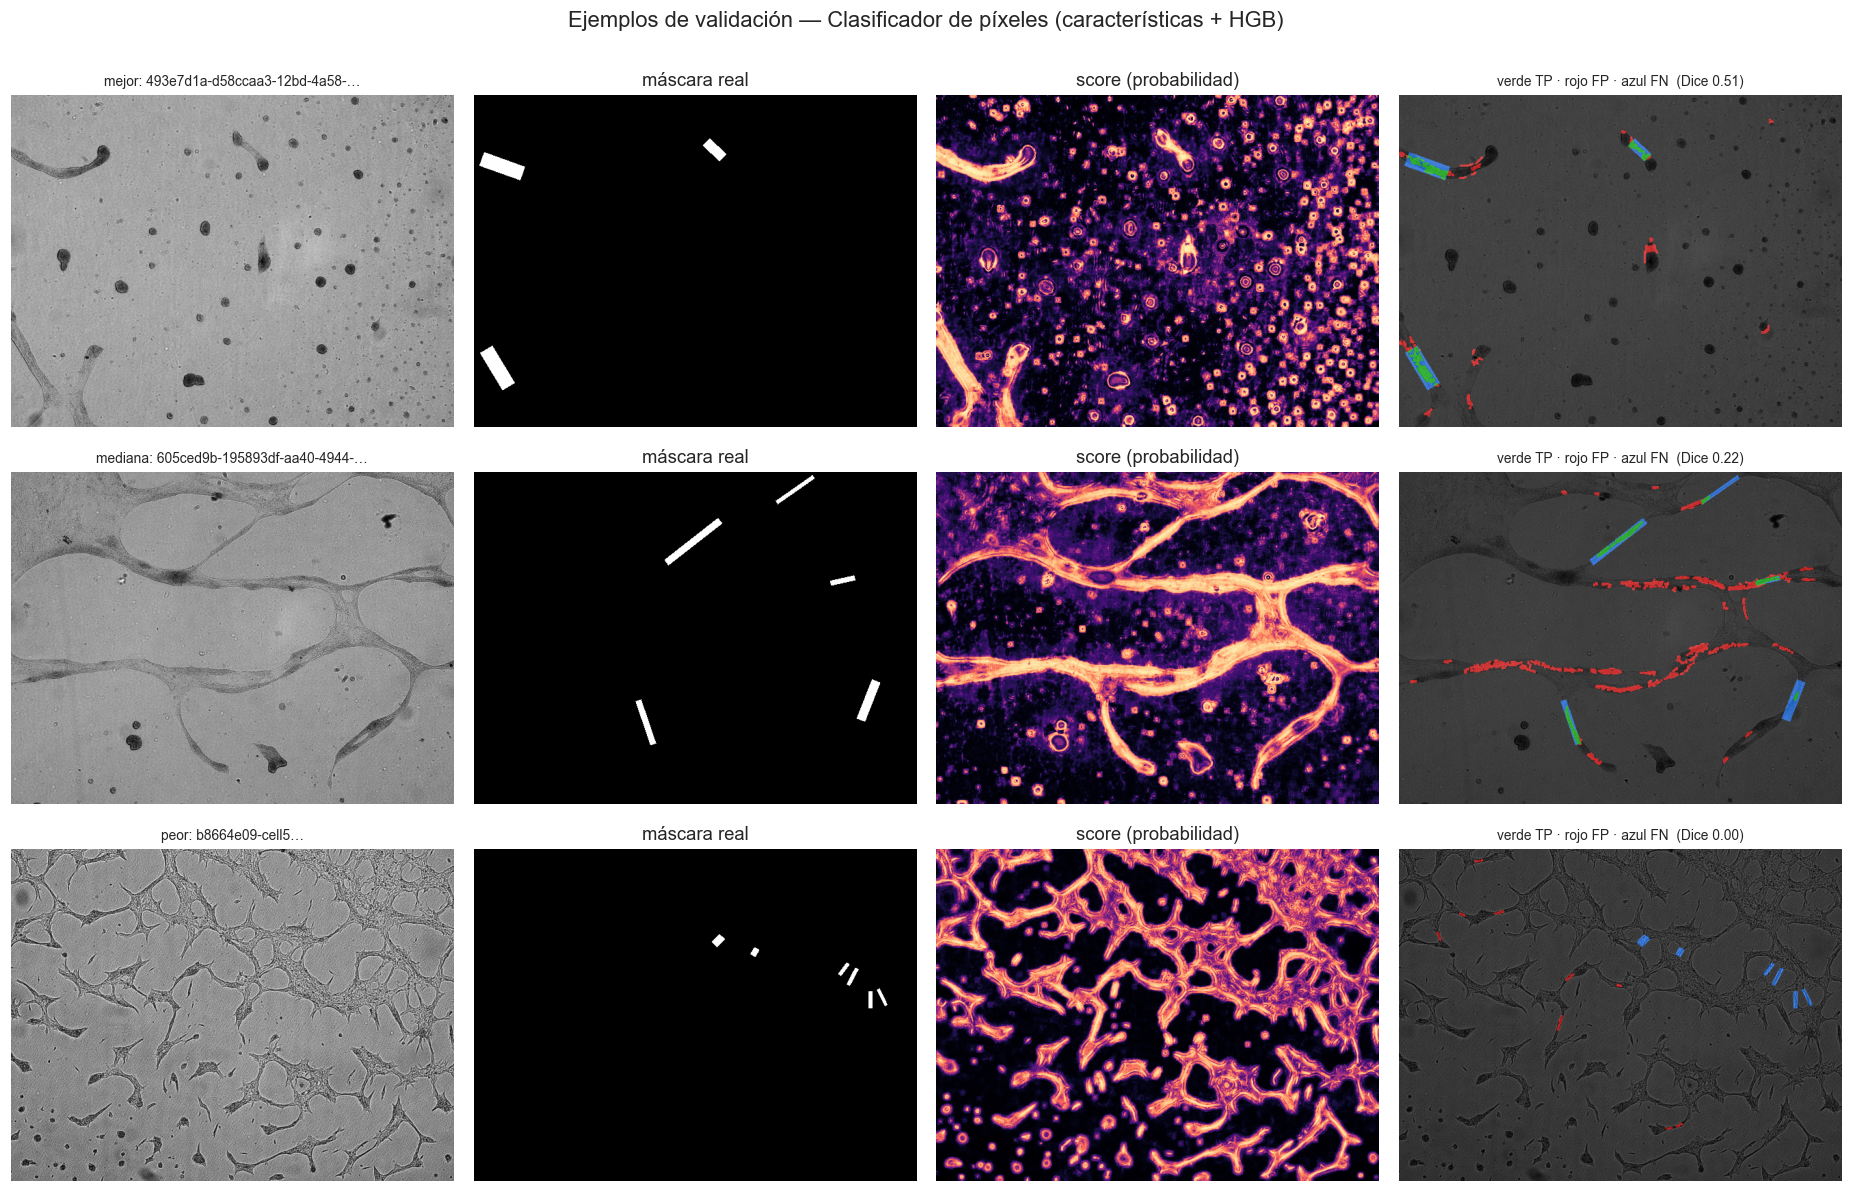

In [16]:
# Ejemplos cualitativos: mejor, mediana y peor imagen (según Dice del mejor modelo)
best = max(resultados, key=lambda k: resultados[k]["summary"]["PR-AUC (AP)"])
orden = pi[best].sort_values("Dice")
sel = [orden.index[-1], orden.index[len(orden) // 2], orden.index[0]]
etiquetas = ["mejor", "mediana", "peor"]

fig, axes = plt.subplots(3, 4, figsize=(17, 11))
for row, (i, et) in enumerate(zip(sel, etiquetas)):
    it, p = val_items[i], preds[best][i]
    y, yp = it["mask"].astype(bool), p["pred"].astype(bool)
    err = np.zeros((*y.shape, 3)); err[y & yp] = (0, .8, 0); err[~y & yp] = (1, 0, 0); err[y & ~yp] = (0, .4, 1)
    axes[row, 0].imshow(it["img"], cmap="gray"); axes[row, 0].set_title(f"{et}: {it['stem'][:28]}…", fontsize=9)
    axes[row, 1].imshow(y, cmap="gray"); axes[row, 1].set_title("máscara real")
    axes[row, 2].imshow(p["score"], cmap="magma", vmin=0, vmax=1); axes[row, 2].set_title("score (probabilidad)")
    axes[row, 3].imshow(it["img"], cmap="gray"); axes[row, 3].imshow(err, alpha=.6)
    axes[row, 3].set_title(f"verde TP · rojo FP · azul FN  (Dice {pi[best].loc[i, 'Dice']:.2f})", fontsize=9)
    for a in axes[row]: a.axis("off")
plt.suptitle(f"Ejemplos de validación — {modelos[best].name}", y=1.0)
plt.tight_layout(); plt.savefig(FIG / "fig_cualitativo.png", bbox_inches="tight", dpi=130); plt.show()

## 9. Exportar resultados para el reporte

In [17]:
resumen = {
    "config": CFG,
    "particion": {k: int(v) for k, v in df_split["split"].value_counts().items()},
    "info_particion": info_split,
    "fuga": {"naive_media": float(naive.mean()), "naive_std": float(naive.std()),
             "naive_max": float(naive.max()), "agrupada": float(agrup),
             **{k: int(v) for k, v in fuga_dup.items()},
             "pares_anotacion_distinta_iou<0.9": int((pairs["iou_mascaras"] < 0.9).sum())},
    "desbalance": tabla_desb.round(4).reset_index().to_dict(orient="records"),
    "metricas_validacion": {modelos[k].name: r["summary"] for k, r in resultados.items()},
    "umbrales_train": {modelos[k].name: modelos[k].threshold_ for k in modelos},
}
with open(REP / "resumen_resultados.json", "w", encoding="utf-8") as f:
    json.dump(resumen, f, indent=2, ensure_ascii=False, default=str)

print("Tablas  :", sorted(p.name for p in REP.glob("*.*")))
print("Figuras :", sorted(p.name for p in FIG.glob("*.png")))

Tablas  : ['LEEME.txt', 'confusion_A_clasica.csv', 'confusion_B_pixeles.csv', 'metricas_por_imagen_val.csv', 'metricas_validacion.csv', 'pares_duplicados.csv', 'por_clase_A_clasica.csv', 'por_clase_B_pixeles.csv', 'resumen_resultados.json', 'tabla_desbalance.csv', 'tabla_fuga.csv']
Figuras : ['fig_confusion.png', 'fig_cualitativo.png', 'fig_desbalance.png', 'fig_etiqueta.png', 'fig_fuga.png', 'fig_por_imagen.png', 'fig_pr_roc.png']


## Observaciones

*(Se completan con los resultados de esta corrida para el reporte.)*